# Floquet Analysis of the Halo Families — Rotation Numbers

Graphs the Floquet (monodromy) analysis of the L1 and L2 halo families. For a
periodic orbit the monodromy matrix $M$ (the STM after one period) has six
multipliers arranged in reciprocal pairs:

- a **hyperbolic** pair $(\lambda, 1/\lambda)$, real, $|\lambda|\neq 1$ — the
  unstable/stable manifold directions,
- a **trivial** pair pinned at $+1$ (a defective $(1,1)$ Jordan block: the flow
  direction and the energy direction), and
- a **center** pair $e^{\pm i\theta}$ on the unit circle — the *elliptic*
  direction that carries the second frequency of a quasi-periodic torus.

The center pair is the whole point: its rotation number $\rho = \theta/2\pi$ is
the transverse winding of the torus that surrounds the orbit. This notebook
extracts $\rho$ along both families (`sweep_rotation_numbers` in `orbits.py`,
which calls the stateless `halo_stability` in `cr3bp_3d.py`) and shows three
views:

1. **Rotation-number landscape** — $\rho$ vs family index and vs Jacobi
   constant, with the low-order resonances a first torus should avoid.
2. **Multipliers on the unit circle** — snapshots along the L1 family showing
   the center pair migrate, reach $-1$ (period-doubling), and leave the circle.
3. **Stability magnitude** — the largest multiplier modulus along each family,
   marking where the torus-supporting (elliptic) region lives.

*Runs from `notebooks/`; imports the library from `../src`.*

In [1]:
import sys, os, contextlib
sys.path.insert(0, '../src')   # adjust if cr3bp*.py / orbits.py live elsewhere
sys.path.insert(0, '.')

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
%matplotlib inline

# Importing orbits.py runs the exploratory script at the top of that file,
# which prints a wall of setup output. Silence just the import.
with open(os.devnull, 'w') as _dn, contextlib.redirect_stdout(_dn):
    import orbits

from orbits import (compute_halo_family, halo_periodicity_constraint,
                    family_tangent, sweep_rotation_numbers)
from cr3bp_3d import (richardson_halo_seed, halo_corrector, halo_stability,
                      MU_EARTH_MOON as MU)
mu = MU

## Seed both families and sweep the rotation number

Each family is seeded with a Richardson third-order guess, polished by the
differential corrector, and continued with the PAC engine. `sweep_rotation_numbers`
then anchors on the cleanest single-center orbit (the $\theta\approx 90^\circ$
orbit in the first clean block) and follows the center pair outward by
eigenvector overlap, unwrapping $\theta$ continuously through the $180^\circ$
period-doubling and stopping when the pair leaves the circle.

In [2]:
def first_orbit(point, Az=0.05, northern=True):
    """Richardson seed -> corrector -> one on-family halo X = [x0, z0, vy0, T_half]."""
    seed_flag = northern if point == 'L1' else (not northern)   # +z at both points
    seed, _, _ = richardson_halo_seed(Az, mu, point=point, northern=seed_flag)
    s0, T, ok = halo_corrector(seed, mu)
    if not ok:
        raise RuntimeError(f"{point} seed failed to converge")
    return np.array([s0[0], s0[2], s0[4], T / 2])

def amplitude_direction(X):
    """PAC tangent pointed toward growing |z0| (deeper into the family)."""
    _, dF, _ = halo_periodicity_constraint(X, mu)
    t = family_tangent(dF)
    return t if np.sign(t[1]) == np.sign(X[1]) else -t

families, sweeps = {}, {}
for point in ['L1', 'L2']:
    X0  = first_orbit(point)
    fam = compute_halo_family(X0, ds=0.01, n_orbits=130, mu=mu,
                              initial_direction=amplitude_direction(X0),
                              verbose=False)
    families[point] = fam
    sweeps[point]   = sweep_rotation_numbers(fam, mu)
    s = sweeps[point]
    print(f"{point}: {len(fam)} orbits | center tracked over "
          f"{s['index'].min():>3}..{s['index'].max():<3} | "
          f"rho {s['rho'].min():.3f} -> {s['rho'].max():.3f} | anchor orbit {s['anchor']}")

L1: 130 orbits | center tracked over   0..52  | rho 0.008 -> 0.696 | anchor orbit 15
L2: 130 orbits | center tracked over   0..52  | rho 0.009 -> 0.493 | anchor orbit 24


## 1. Rotation-number landscape

$\rho$ along each family. The dashed lines are the low-order rationals
($1/4,\,1/3,\,2/5,\,1/2,\,3/5,\,2/3$): near these the invariant circle
degenerates into a periodic orbit of the return map and a QPIT solver stalls,
so a first target wants $\rho$ sitting comfortably between them. The red stars
mark the suggested first-torus orbits (both between $1/4$ and $1/3$).

L1 is non-monotonic — the center pair climbs past its period-doubling to
$\rho\approx 0.70$, then reverses and returns to $-1$, leaving the circle near
orbit 53 (the NRHO regime beyond has no torus). L2 climbs cleanly and
monotonically to $\rho\approx 0.48$ across its first ~52 orbits.

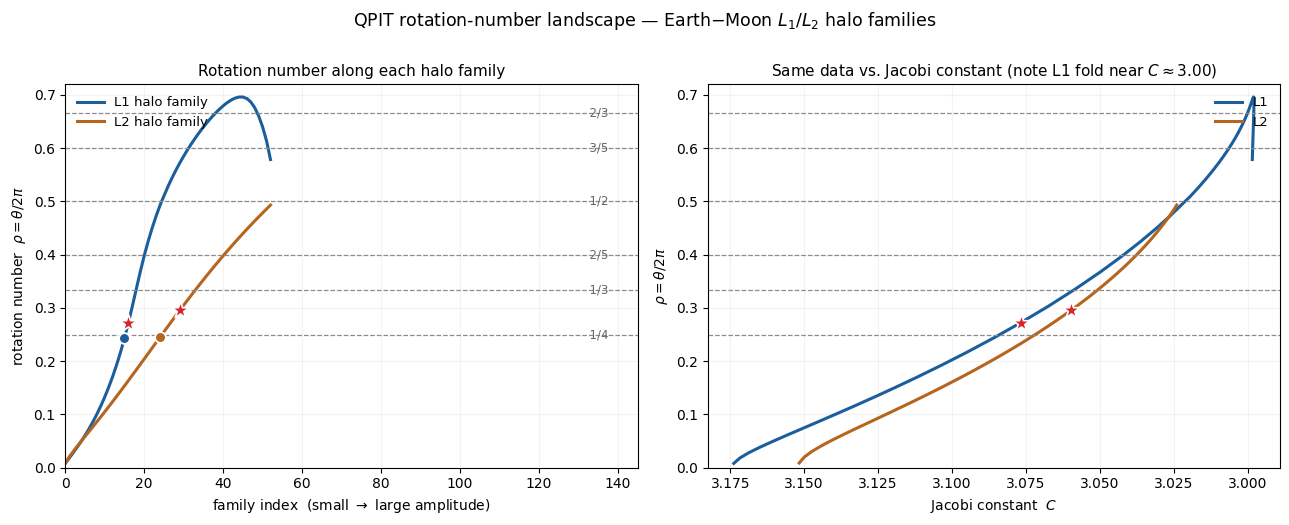

In [3]:
resonances = [('1/4', 0.25), ('1/3', 1/3), ('2/5', 0.4),
               ('1/2', 0.5), ('3/5', 0.6), ('2/3', 2/3)]
colors  = {'L1': '#1b5e9c', 'L2': '#b5651d'}
targets = {'L1': 16, 'L2': 29}   # suggested first-torus orbits

fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))

# --- (a) rho vs family index ---
for pt in ['L1', 'L2']:
    s = sweeps[pt]
    ax[0].plot(s['index'], s['rho'], '-', lw=2.2, color=colors[pt], label=f'{pt} halo family')
    j = list(s['index']).index(s['anchor'])
    ax[0].scatter([s['anchor']], [s['rho'][j]], s=60, color=colors[pt],
                  edgecolor='white', linewidth=1.3, zorder=5)
    jt = int(np.argmin(np.abs(s['index'] - targets[pt])))
    ax[0].scatter([s['index'][jt]], [s['rho'][jt]], s=170, marker='*',
                  color='#d62728', edgecolor='white', linewidth=1.2, zorder=6)
for name, val in resonances:
    ax[0].axhline(val, color='0.55', ls='--', lw=0.9)
    ax[0].text(131, val, f'  {name}', va='center', fontsize=8.5, color='0.4')
ax[0].set_xlabel('family index  (small $\\to$ large amplitude)')
ax[0].set_ylabel(r'rotation number  $\rho = \theta / 2\pi$')
ax[0].set_title('Rotation number along each halo family', fontsize=11)
ax[0].set_xlim(0, 145); ax[0].set_ylim(0, 0.72)
ax[0].legend(loc='upper left', frameon=False, fontsize=9.5)
ax[0].grid(alpha=0.15)

# --- (b) rho vs Jacobi constant ---
for pt in ['L1', 'L2']:
    s = sweeps[pt]
    ax[1].plot(s['C'], s['rho'], '-', lw=2.2, color=colors[pt], label=pt)
    jt = int(np.argmin(np.abs(s['index'] - targets[pt])))
    ax[1].scatter([s['C'][jt]], [s['rho'][jt]], s=170, marker='*',
                  color='#d62728', edgecolor='white', linewidth=1.2, zorder=6)
for name, val in resonances:
    ax[1].axhline(val, color='0.55', ls='--', lw=0.9)
ax[1].set_xlabel('Jacobi constant  $C$')
ax[1].set_ylabel(r'$\rho = \theta / 2\pi$')
ax[1].set_title('Same data vs. Jacobi constant (note L1 fold near $C\\approx 3.00$)', fontsize=11)
ax[1].invert_xaxis(); ax[1].set_ylim(0, 0.72)
ax[1].legend(loc='upper right', frameon=False, fontsize=9.5)
ax[1].grid(alpha=0.15)

fig.suptitle('QPIT rotation-number landscape — Earth$-$Moon $L_1$/$L_2$ halo families',
             fontsize=12.5, y=1.00)
fig.tight_layout()
plt.show()

## 2. Monodromy multipliers on the unit circle

Snapshots along the **L1** family. Points are colored purely by where they land
(no tracking): **green** = the trivial pair at $+1$, **red** = an elliptic pair
on the circle, **gray** = a hyperbolic pair off the circle (its real value is
annotated when it sits outside the frame).

Read left to right, top to bottom: at small amplitude the center pair sits just
off $+1$ ($\rho$ small) while the hyperbolic pair is enormous; it swings up the
circle, reaches $-1$ at the **period-doubling** (orbit 24), climbs past it, and
by orbit 53 has come back down and is leaving the circle onto the negative real
axis. By orbit 72 both non-trivial pairs are real — the halo is fully
hyperbolic and no torus exists. (L2 differs: its center pair never leaves the
circle across the tracked range.)

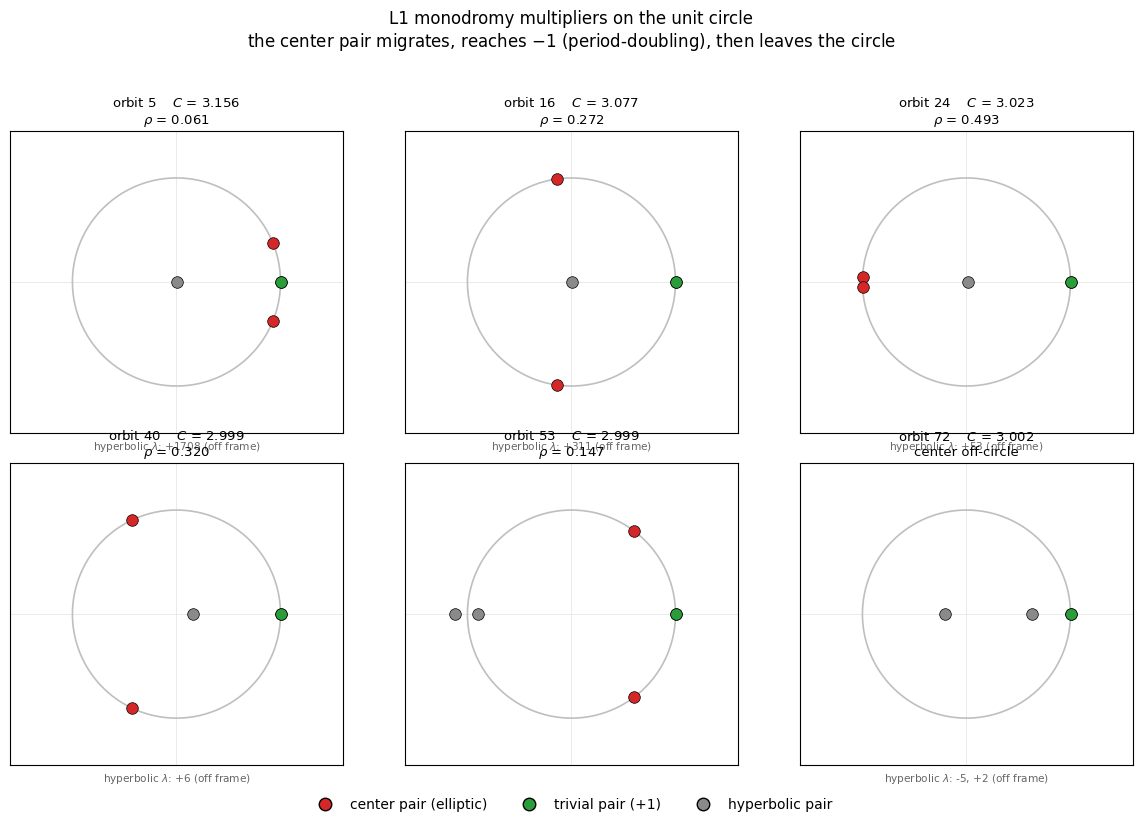

In [4]:
snapshot = [5, 16, 24, 40, 53, 72]   # L1: small -> period-doubling -> past-peak -> leaving -> gone
fam = families['L1']
circ = np.linspace(0, 2*np.pi, 240)
TRIV, ELL, HYP = '#2a9d3a', '#d62728', '#8a8a8a'

fig, axes = plt.subplots(2, 3, figsize=(12, 8.2))
for ax, oi in zip(axes.flat, snapshot):
    r = halo_stability(fam[oi]['state0'], fam[oi]['period'], mu)
    ax.plot(np.cos(circ), np.sin(circ), color='0.75', lw=1.2, zorder=1)
    ax.axhline(0, color='0.9', lw=0.6, zorder=0)
    ax.axvline(0, color='0.9', lw=0.6, zorder=0)
    off_frame = []
    for m in r['multipliers']:
        if abs(m - 1.0) < 1e-3:
            col = TRIV
        elif abs(abs(m) - 1.0) < 1e-3:
            col = ELL
        else:
            col = HYP
        if abs(m.real) > 1.55 or abs(m.imag) > 1.35:
            off_frame.append(m.real)
            continue
        ax.scatter(m.real, m.imag, s=70, color=col, edgecolor='k',
                   linewidth=0.5, zorder=5)
    rho_txt = (f"$\\rho$ = {np.degrees(r['theta'])/360:.3f}"
               if r['center'] is not None else "center off-circle")
    ax.set_title(f"orbit {oi}    $C$ = {fam[oi]['jacobi']:.3f}\n{rho_txt}", fontsize=9.5)
    if off_frame:
        note = ", ".join(f"{v:+.0f}" for v in sorted(off_frame))
        ax.text(0.5, -0.02, f"hyperbolic $\\lambda$: {note} (off frame)",
                transform=ax.transAxes, ha='center', va='top', fontsize=7.6, color='0.4')
    ax.set_aspect('equal'); ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.45, 1.45)
    ax.set_xticks([]); ax.set_yticks([])

handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=c,
                  markeredgecolor='k', markersize=9, label=l)
           for c, l in [(ELL, 'center pair (elliptic)'),
                        (TRIV, 'trivial pair (+1)'),
                        (HYP, 'hyperbolic pair')]]
fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False, fontsize=10)
fig.suptitle('L1 monodromy multipliers on the unit circle\n'
             'the center pair migrates, reaches $-1$ (period-doubling), then leaves the circle',
             fontsize=12, y=0.99)
fig.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()

## 3. Stability magnitude along each family

The largest multiplier modulus $\max|\mu|$ (log scale) measures how unstable
each halo is. The shaded band marks where a genuine center pair sits on the
circle — the **torus-supporting** region. Small halos are strongly hyperbolic
($\max|\mu|\sim 10^3$); the instability weakens toward the middle of the L1
family (a brief near-stable window where the hyperbolic pair itself touches the
circle), then strengthens again into the NRHO regime once the center pair has
left. L2 stays mildly unstable and elliptic throughout the tracked range.

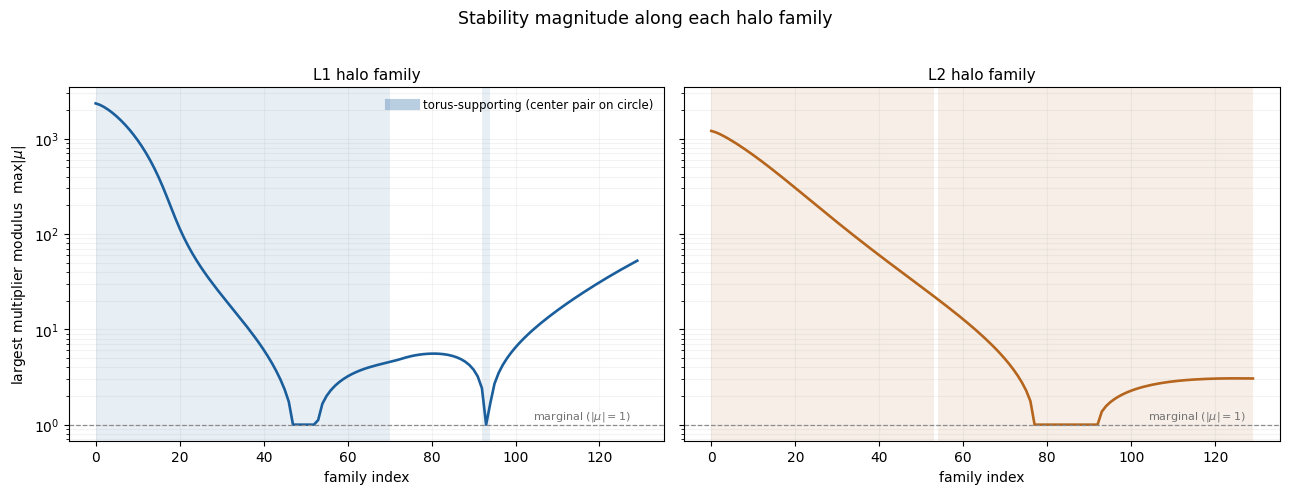

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for k, pt in enumerate(['L1', 'L2']):
    fam = families[pt]
    idx = np.arange(len(fam))
    maxmod, has_center = [], []
    for o in fam:
        r = halo_stability(o['state0'], o['period'], mu)
        maxmod.append(max(abs(m) for m in r['multipliers']))
        has_center.append(r['center'] is not None)
    maxmod = np.array(maxmod); has_center = np.array(has_center)

    ax[k].semilogy(idx, maxmod, '-', lw=1.9, color=colors[pt])
    ax[k].axhline(1.0, color='0.55', ls='--', lw=0.9)
    ax[k].text(len(fam)*0.98, 1.02, 'marginal ($|\\mu|=1$)', ha='right',
               va='bottom', fontsize=8, color='0.45')
    # shade contiguous torus-supporting spans
    in_span = False
    for i, c in enumerate(has_center):
        if c and not in_span:
            start = i; in_span = True
        if in_span and (not c or i == len(has_center)-1):
            end = i if not c else i
            ax[k].axvspan(start, end, color=colors[pt], alpha=0.10, lw=0)
            in_span = False
    ax[k].set_title(f'{pt} halo family', fontsize=11)
    ax[k].set_xlabel('family index')
    ax[k].grid(alpha=0.15, which='both')
ax[0].set_ylabel(r'largest multiplier modulus  $\max|\mu|$')
# legend for the shaded band
band = Line2D([0], [0], color=colors['L1'], alpha=0.3, lw=8,
              label='torus-supporting (center pair on circle)')
ax[0].legend(handles=[band], loc='upper right', frameon=False, fontsize=8.5)
fig.suptitle('Stability magnitude along each halo family', fontsize=12.5, y=1.02)
fig.tight_layout()
plt.show()